# $\textbf{Analytics of ML Features Usage in IDEs}$
### Author: Martyna Czyż from Poland


## Table of Contents
1. [Introduction ](#wstep)
   - [1.1 Dataset description](#dateset)
   - [1.2 Importing Data](#importing-data)
   - [1.3 Data Quality Check](#data-quality-check)
   - [1.4 Project Objective](#project-objective)
2. [Users analysis](#user-analysis)
   - [2.1 Number of users in each license group](#number-of-useres)
   - [2.2 Number of active users per week (Single-License Users Only)](#number-of-active)
3. [Users activity in each license type](#user-activity)
   - [3.1 Comparison of users requests across weekdays for diffrent licenses](#comparison-of-users-weekdays)
   - [3.2 Average spending of units (credits) per User in the span of 3 months for each license](#average-spending-per-user)
      - [3.2.1 Users with Exceptionally High/Low Spending Amounts](#high-low)
      - [3.2.2 Average spending per user (without outliers) - monthly credit limits](#wth_outliers)
4. [Model Usage Analysis](#model-usage-analysis)
   - [4.1 Percentage utilization of models across each license (based on the number of requests)](#percentage-utilization)
   - [4.2 Total credits spent per model](#total-credits-spent-per-model)
   - [4.3 Which Models Do Users Prefer? Feature-Based Usability Analysis](#which-models)
   - [4.4 Average Cost per request by model](#average-cost-per-request-by-model)
5. [Further analysis of features accross different data](#further-features)
   - [5.1 Feature Usage and Associated Spending across Licenses](#feture-usage)
   - [5.2 Total Requests and Spent Amount per Feature](#total-requests-and-spent-amount-per-feature)
   - [5.3 Average Cost per Request by Feature](#average-cost-per-request-by-feature)
6. [Analysis of Users with Multiple License](#mulitply-license)
   - [6.1 Number of License Changes per User](#number-of-change)
   - [6.2 Comparison of Two License Usages in Requests and Spending](#comparison-of-two-license)
   - [6.3 Model usage by licenses for selected users](#model-usage-by-licenses-for)
7. [Summary and recomandation](#summary-and-recomandation)
   - [7.1 Conclusions from every chapter](#conclusions)
   - [7.2 Recommendations](#recommendations)

## <h2 id="wstep">1. Introduction</h2>
This is an analysis of user activity within an IDE environment over the period from March to May 2025. The dataset provides insight into how users interact with various language models, license types and available system features. Each record represents user’s daily activity, including the number of requests made and the amount of credits spent. This structure enables the examination of how different user groups utilize system resources, which features are most actively used and also aims to identify potential behavioral differences related to license level or the type of language model applied.
## <h4 id="dateset">1.1 Dataset description</h4>
The dataset contains the following variables:

**uuid** – unique user identifier allowing differentiation of user activity while maintaining anonymity.

**day_id** – identifier of the day when the user activity occurred.

**license** – user license type defining the access level to the system.

**model** – type of large language model (LLM) used.

**feature** – type of functionality used within the system

**requests_cnt** – number of requests made by the user during the given day.

**spent_amount** – amount of credits spent within the day by the user.

## <h4 id="importing-data">1.2 Importing Data</h4>
The following Python libraries were used for the analysis:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

- pandas – for data manipulation and aggregation,

- numpy – for numerical calculations,

- matplotlib and seaborn – for data visualization.

In [2]:
df = pd.read_csv('da_internship_task_dataset.csv')

After importing the dataset, let us examine the types of licenses, models, and features present in the data.

In [3]:
print("Types of licenses:", df['license'].unique())
print("Types of models:", df['model'].unique())
print("Types of features:", df['feature'].unique())

Types of licenses: ['Premium' 'Basic' 'Enterprise' 'Standard']
Types of models: ['Model_A' 'Model_B' 'Model_D' 'Model_E' 'Model_C']
Types of features: ['Feature_1' 'Feature_2' 'Feature_3' 'Feature_5' 'Feature_4']


I have created additional time-based columns (month, week, day) that will be used in subsequent data analysis.
They allow for easy grouping and comparison of user activity and spending by month, week and day. Below there is a table with 5 sample users, showcasing all data groups used for the analysis in this project.

In [4]:
df['day_id'] = pd.to_datetime(df['day_id'], errors='coerce')

df['month'] = df['day_id'].dt.month
df['week'] = df['day_id'].dt.isocalendar().week
df['day'] = df['day_id'].dt.day

display(df.head())

,uuid,day_id,license,model,feature,requests_cnt,spent_amount,month,week,day
0,user_920,2025-05-01,Premium,Model_A,Feature_1,44.0,16.38,5,18,1
1,user_717,2025-03-04,Premium,Model_B,Feature_2,72.0,27.92,3,10,4
2,user_610,2025-05-08,Premium,Model_A,Feature_2,27.0,9.87,5,19,8
3,user_94,2025-03-11,Basic,Model_D,Feature_1,76.0,14.67,3,11,11
4,user_920,2025-05-14,Premium,Model_E,Feature_3,47.0,9.88,5,20,14


## <h4 id="data-quality-check">1.3 Data Quality Check</h4>

In this section I verifed the completeness and consistency of the provided data.

I checked for missing values and duplicate rows that could affect the analysis results.
Additionally, I identified potential data issues, such as outliers, unusual values in numeric columns or logical errors, which could distort the interpretation of results.

In [5]:
print("\nNumber of missing values in each column:")
print(df.isna().sum())


Number of missing values in each column:
uuid            0
day_id          0
license         0
model           0
feature         0
requests_cnt    0
spent_amount    0
month           0
week            0
day             0
dtype: int64


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


The dataset was checked for missing values and duplicate rows.
No missing values were found in any of the columns, indicating complete data coverage.
Additionally, no duplicate rows were detected.
Overall, the dataset is consistent and reliable for analysis.

In [7]:
df[['requests_cnt', 'spent_amount']].describe()

,requests_cnt,spent_amount
count,122746.000000,122746.000000
mean,51.260742,12.227798
std,167.977380,37.588494
min,1.000000,0.270000
25%,18.000000,5.140000
50%,32.000000,8.020000
75%,54.000000,13.060000
max,12900.000000,2599.000000


**reques_cnt** - the average number of daily requests is approximately 51 with a median of 32, while the maximum value reaches 12,900.
This indicates that most users generate a moderate amount of activity, whereas a small subset of users performs an exceptionally large number of requests.
The high standard deviation (≈168) confirms significant dispersion and the presence of outliers.

**spent_amount** - the average spending per day is 12.23 units, with a median of 8.02 and a maximum of 2,599 units.
This suggests that most users spend only a few units per day, while a small group of users accounts for a disproportionately high share of total spending.
The data distribution is strongly right-skewed, dominated by low values with a few extreme outliers that inflate the mean.

## <h4 id="project-objective">1.4 Project Objective</h4>
The objective of this project is to provide a comprehensive analysis of user behavior and platform usage across different license types. The analysis aims to enable the company to:

- assess the effectiveness and structure of current licensing plans,

- identify user activity patterns and system load distribution,

- understand differences in feature and model usage across all customer segments,

- analyze the user credit consumption intensity,

- detect exceptional or anomalous usage patterns,

- analyze users with multiple licenses and the impact of license changes on their behavior,

- develop recommendations that support refining the offers, adjusting credit limits and planning system resources effectively.

The insights generated in this report offer evidence-based guidance for decisions across strategy and operations, capacity planning, license optimization and product development.

## <h2 id="user-analysis">2. Users analysis</h2>
This section presents a comparative analysis of users across all license types — Basic, Standard, Premium, and Enterprise.
The goal of this analysis is to identify what license types are most frequently chosen and how user activity varies among them.

#####  <h4 id="number-of-useres">2.1 Number of users in each license group</h4>

At the start of the analysis, the data was organized by grouping users according to license type and counting the number of users within each category. As a result, the following table was obtained, showing the distribution of users across different license types over a three-month period:

In [8]:
unique_users = df[['uuid', 'license']].drop_duplicates()
order = ['Basic', 'Standard', 'Premium', 'Enterprise']

users_by_license = (unique_users['license'].value_counts().rename_axis('license').reset_index(name='number_of_users'))
users_by_license['license'] = pd.Categorical(users_by_license['license'], categories=order, ordered=True)
users_by_license = users_by_license.sort_values('license')

print("Summary of License Types in the span of 3 months:")
display(users_by_license)

print("Total number of users:", users_by_license['number_of_users'].sum())


Summary of License Types in the span of 3 months:


,license,number_of_users
0,Basic,717
1,Standard,708
3,Premium,247
2,Enterprise,251


Total number of users: 1923


However, after removing duplicate user entries and counting only unique individuals using the licenses, we get the following outcome:

In [9]:
df_unique_users = df.drop_duplicates(subset='uuid')
unique_user_count = df_unique_users['uuid'].nunique()

print(f"Total number of users: {unique_user_count}")

Total number of users: 1866


The discrepancies arise from the fact that some users were associated with more than one license during the analyzed period. Let’s examine how frequently they changed their licenses and how many of such users were there.

In [10]:
license_counts_per_user = df.groupby("uuid")["license"].nunique()
users_with_changed_license = license_counts_per_user[license_counts_per_user > 1]
num_users_changed_license = len(users_with_changed_license)
max_license_changes = license_counts_per_user.max()

print("Number of users who changed their license type during the three month period:", num_users_changed_license)
print("Maximum number of different license types used by a single user:", max_license_changes)

Number of users who changed their license type during the three month period: 57
Maximum number of different license types used by a single user: 2


In this section, we exclude users who changed their licenses. Their behavior will be examined in detail in a separate chapter.

Here, we focus on users who maintained a consistent license throughout the entire observation period. This approach allows us to better understand which models are the most popular among stable users and to draw insights regarding their preferences and potential directions for product development.

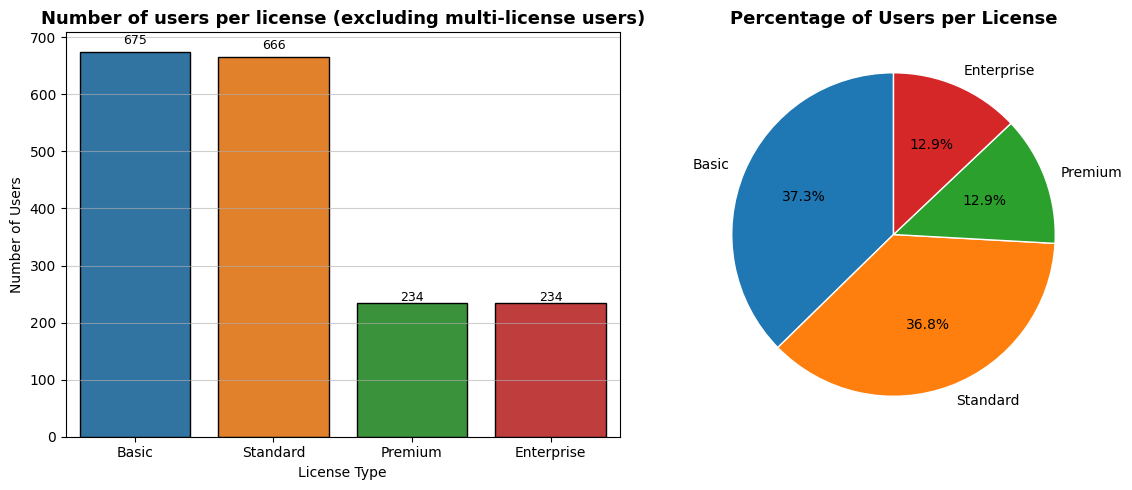

In [11]:
df_copy = df.copy()
license_counts_per_user = df_copy.groupby("uuid")["license"].nunique()
users_single_license = license_counts_per_user[license_counts_per_user == 1].index

filtered_df = df_copy[df_copy["uuid"].isin(users_single_license)].copy()
summary2 = filtered_df.groupby("license")["uuid"].nunique().reset_index(name="number_of_users")
summary2['license'] = pd.Categorical(summary2['license'], categories=order, ordered=True)
summary2 = summary2.sort_values('license')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    x='license', y='number_of_users', data=summary2, hue='license', dodge=False, legend=False, order=order, ax=axes[0], edgecolor="black")
axes[0].set_title('Number of users per license (excluding multi-license users)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('License Type')
axes[0].set_ylabel('Number of Users')
axes[0].grid(axis='y', alpha=0.6)

for i, val in enumerate(summary2['number_of_users']):
    axes[0].text(i, val + val*0.02, f"{val}", ha='center', fontsize=9)

valid_summary = summary2.dropna(subset=['license'])
axes[1].pie(
    valid_summary['number_of_users'],
    labels=valid_summary['license'],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white'}
)
axes[1].set_title('Percentage of Users per License', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

Based on the presented chart, it can be observed that the highest number of users are using the Basic and Standard plans. This indicates that these groups represent the largest user base but not necessarily the highest revenue.

From a pricing strategy perspective, it would be beneficial to encourage users of lower-tier plans to upgrade to higher-level licenses, for example by slightly limiting the number of available credits or features in the lower plans. Such approach could increase interest in the Premium plan, which generates higher revenue per user and therefore improve the overall profitability of the licensing system.

#####  <h4 id="number-of-active">2.2 Number of Active Users per Week (Single-License Users Only)</h4>

Now let's analyze the number of active users for each license on a weekly basis to determine whether user activity increased over the three-month period (March–May). This analysis will help us identify potential upward or downward trends and assess the stability of user engagement within each license tier.

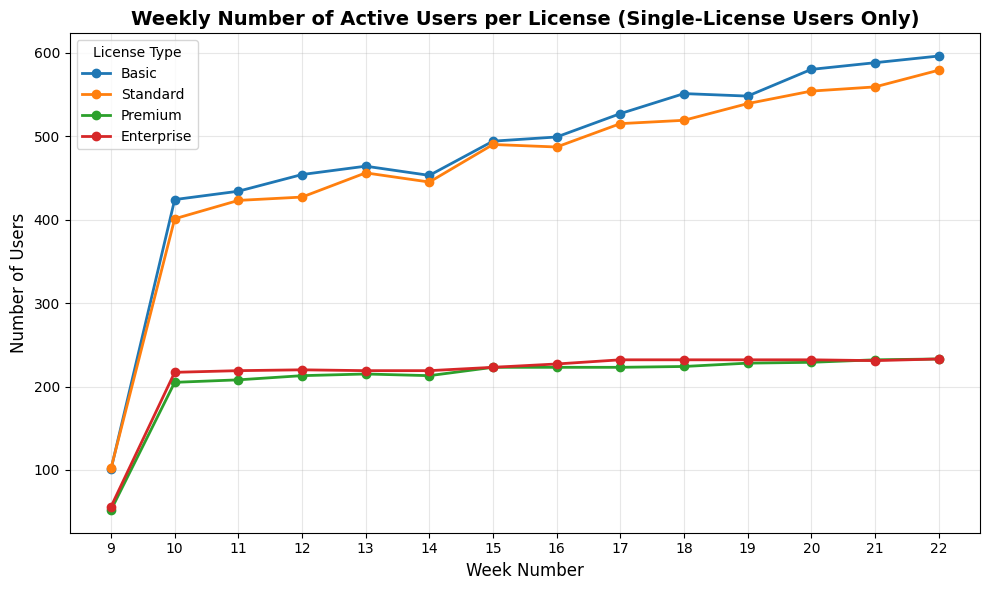

In [12]:
weekly_trends = (
    filtered_df.groupby(["week", "license"])["uuid"]
    .nunique()
    .reset_index(name="number_of_users")
)

weekly_trends["license"] = pd.Categorical(weekly_trends["license"], categories=order, ordered=True)
weekly_trends = weekly_trends.sort_values(["license", "week"])

plt.figure(figsize=(10, 6))

for license_type in order:
    data = weekly_trends[weekly_trends["license"] == license_type]
    plt.plot(data["week"], data["number_of_users"], marker="o", linewidth=2, label=license_type)

plt.title("Weekly Number of Active Users per License (Single-License Users Only)", fontsize=14, fontweight="bold")
plt.xlabel("Week Number", fontsize=12)
plt.ylabel("Number of Users", fontsize=12)
plt.legend(title="License Type", fontsize=10)
plt.grid(alpha=0.3)
plt.xticks(sorted(weekly_trends["week"].unique()))
plt.tight_layout()
plt.show()

In week 9, there is a noticeably lower number of active users, which is due to data being available for only two days during that week. Similarly, the last week includes data from just six days, so values can also be lower then expected.

Over time, user activity within the Basic and Standard licenses shows a gradual upward trend, suggesting growing popularity of these tiers among new users. In contrast, Premium and Enterprise licenses maintain relatively stable activity levels.

**Recomendation:** 

It may be worth to implement initiatives aimed at increasing the appeal of higher-tier licenses (Premium and Enterprise). The observed growth in user activity mainly concerns the lower tiers, which attract new customers but does not sufficiently motivate them to upgrade to more advanced licenses.

## <h2 id="user-activity">3. Users activity in each license type</h2>
This section explores user activity patterns across different license types.
It aims to identify how usage behavior varies depending on the license tier. It includes analysis of the number of requests made on different weekdays and the average amount of units (credits) spent per user. The purpose of this section is to understand how users with different license types engage with the system.
By comparing their activity levels and spending patterns, we can identify usage trends, measure the intensity of system utilization and detect potential differences in behavior between license tiers.

In [13]:
summary = (
    df.groupby('license', as_index=False)
      .agg({
          'spent_amount': 'sum',
          'requests_cnt': 'sum'
      })
)
summary['license'] = pd.Categorical(summary['license'], categories=order, ordered=True)
summary = summary.sort_values('license')

print("\nSummary of total spent amount and requests by license type:")
display(summary)



Summary of total spent amount and requests by license type:


,license,spent_amount,requests_cnt
0,Basic,256253.86,1078123.0
3,Standard,367450.21,1568926.0
2,Premium,403971.50,1719628.0
1,Enterprise,473237.77,1925374.0


#####  <h4 id="comparison-of-users-weekdays">3.1 Comparison of users requests across weekdays for diffrent licenses</h4>
In this section we want to analyse on which weekdays users are the most active, based on their request amount.

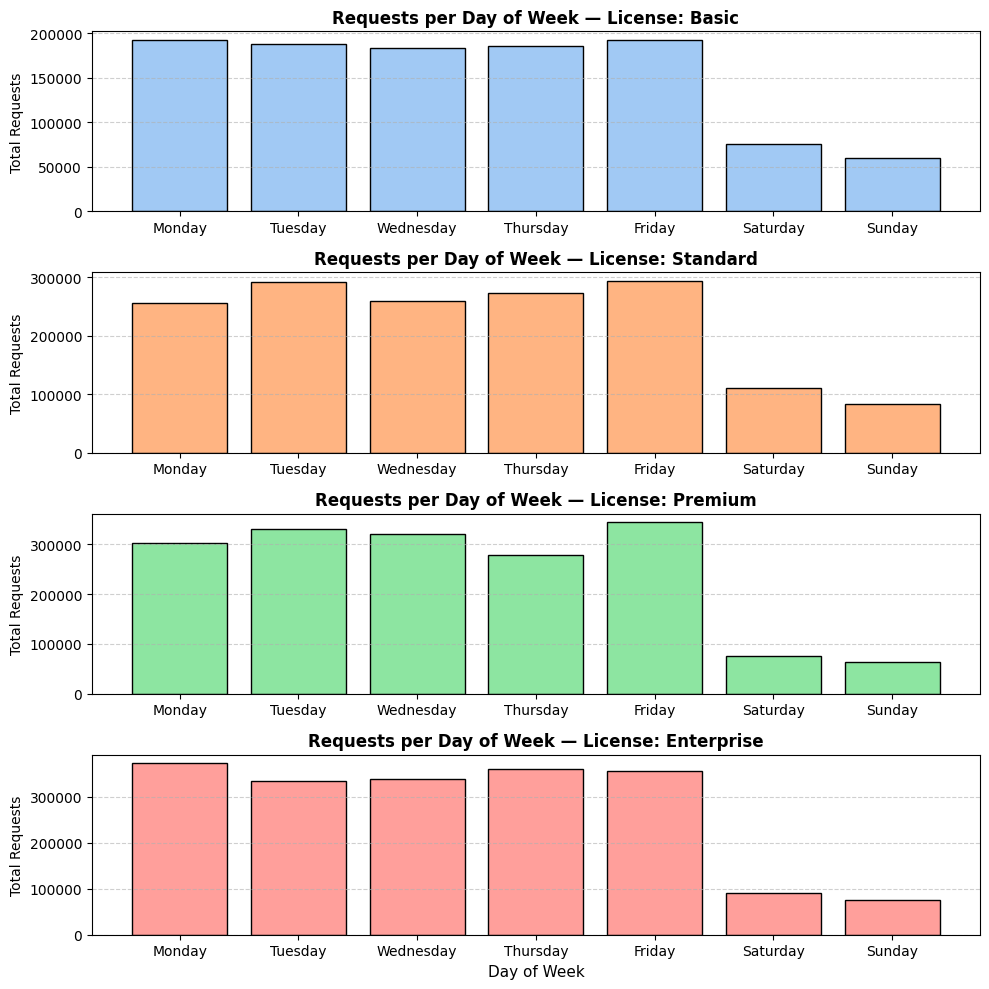

In [14]:
df["week_day"] = df["day_id"].dt.day_name()
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

mi = pd.MultiIndex.from_product([order, days_order], names=["license", "week_day"])

license_weekday_sum = (
    df.groupby(["license", "week_day"])["requests_cnt"]
    .sum()
    .reindex(mi, fill_value=0)
    .reset_index()
)

colors = sns.color_palette("pastel", len(order))

fig, axes = plt.subplots(len(order), 1, figsize=(10, 10))

for ax, (lic, color) in zip(axes, zip(order, colors)):
    subset = license_weekday_sum[license_weekday_sum["license"] == lic]
    ax.bar(subset["week_day"], subset["requests_cnt"], color=color, edgecolor="black")
    ax.set_title(f"Requests per Day of Week — License: {lic}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Total Requests", fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.6)

axes[-1].set_xlabel("Day of Week", fontsize=11)

plt.tight_layout()
plt.show()


As we can see the activity of users does not depend on the licence type. It stays relatively on the same level during a typical workweek which is from Monday till Friday. The request amount is drastically dropping during the weekends, where the activity is over 3 times lower on average. This suggests that people primarly use the models during their worktime.

**Recommendations:**
- Reduce compute capacity during weekends to lower operational costs. 

- Schedule system maintenance, updates, and non-critical deployments for weekends, when user activity is at its lowest.

#####  <h4 id="average-spending-per-user">3.2 Average spending of units (credits) per User in the span of 3 months for each license</h4>

#####  <h5 id="high-low">3.2.1 Users with Exceptionally High/Low Spending Amounts</h5>
First of all we want to eliminate all outliers, which we exclude from the average calculation because they represent extreme or atypical cases that can significantly distort the overall results.
In this dataset, outliers correspond to users who use exceptionally high/low amount of units (credits) compared to the rest of the group. Including them in the average would lead to a misleading interpretation. A user becomes an outlier once their total spending surpasses the upper percentile limit (97th percentile) or under the limit (3th percentile), which we can see on the chart below.


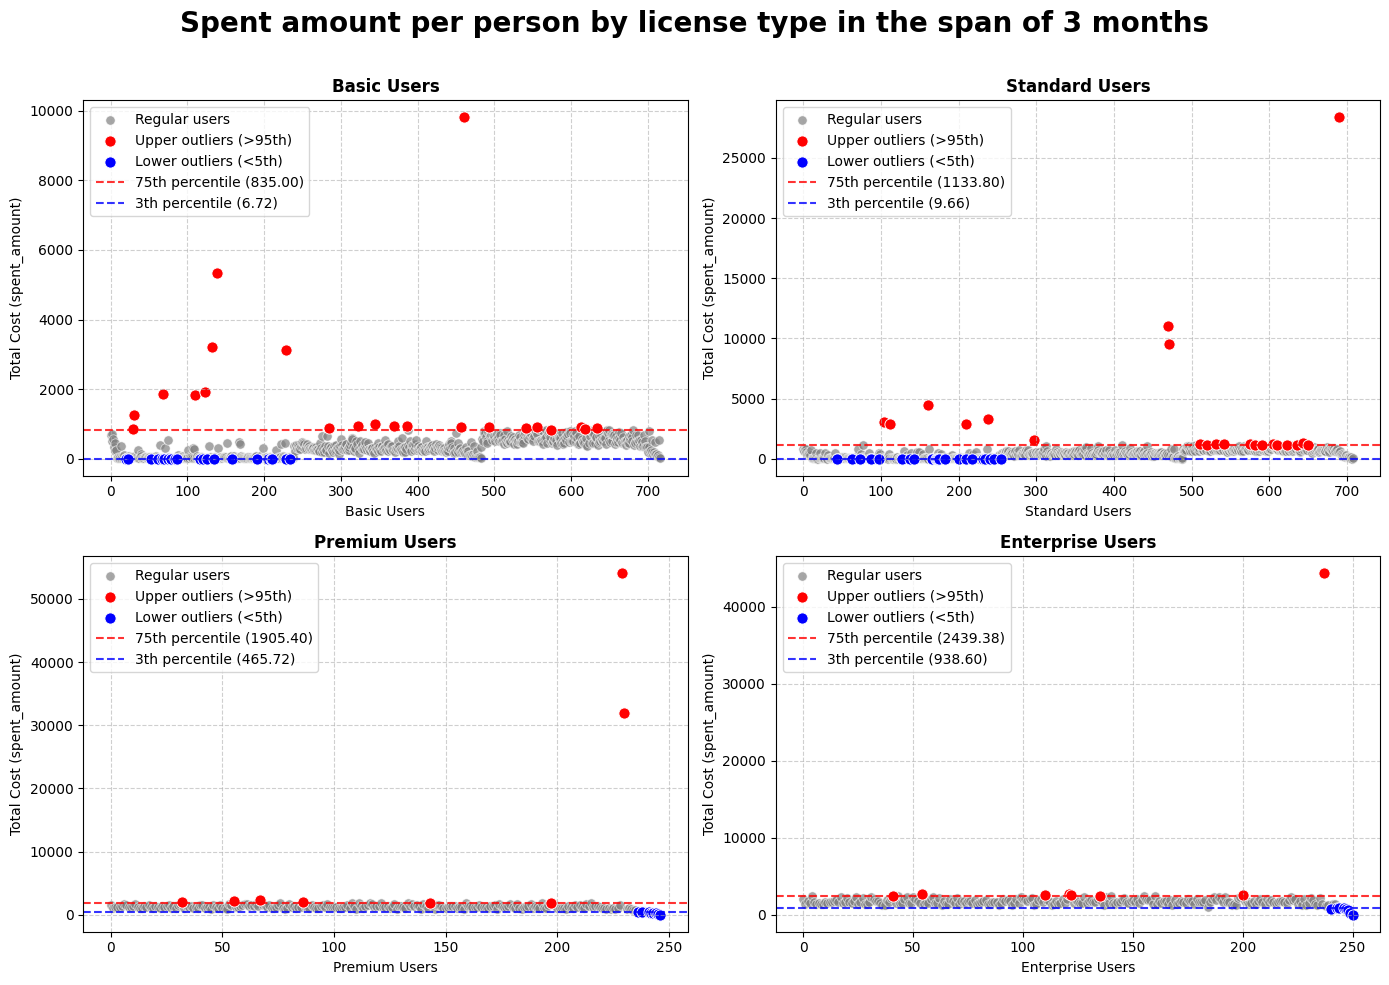

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, lic in enumerate(order):
    users = df[df['license'] == lic]
    usage = users.groupby('uuid')['spent_amount'].sum().reset_index()
    lower_threshold = np.percentile(usage['spent_amount'], 3)
    upper_threshold = np.percentile(usage['spent_amount'], 97)
    upper_outliers = usage[usage['spent_amount'] > upper_threshold]
    lower_outliers = usage[usage['spent_amount'] < lower_threshold]

    sns.scatterplot(x=range(len(usage)), y='spent_amount', data=usage, color='grey', s=45, alpha=0.7, ax=axes[i], label='Regular users')
    if len(upper_outliers) > 0:
        sns.scatterplot(x=upper_outliers.index, y='spent_amount', data=upper_outliers, color='red', s=65, ax=axes[i], label='Upper outliers (>95th)')
    if len(lower_outliers) > 0:
        sns.scatterplot(x=lower_outliers.index, y='spent_amount', data=lower_outliers, color='blue', s=65, ax=axes[i], label='Lower outliers (<5th)')

    axes[i].axhline(y=upper_threshold, color='red', linestyle='--', alpha=0.8, label=f'75th percentile ({upper_threshold:.2f})')
    axes[i].axhline(y=lower_threshold, color='blue', linestyle='--', alpha=0.8, label=f'3th percentile ({lower_threshold:.2f})')

    axes[i].set_title(f'{lic} Users', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(f'{lic} Users')
    axes[i].set_ylabel('Total Cost (spent_amount)')
    axes[i].legend()
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Spent amount per person by license type in the span of 3 months', fontsize=20, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


#####  <h5 id="wth_outliers">3.2.2 Average spending per user (without outliers) - monthly credit limits</h5>
Now, without outliers, I created a graph to examine the average spending per user for each license type over the three-month period.

C:\Users\marcz\AppData\Local\Temp\ipykernel_24956\491815608.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  user_spent_no_outliers = user_spent.groupby('license', group_keys=False).apply(remove_outliers)


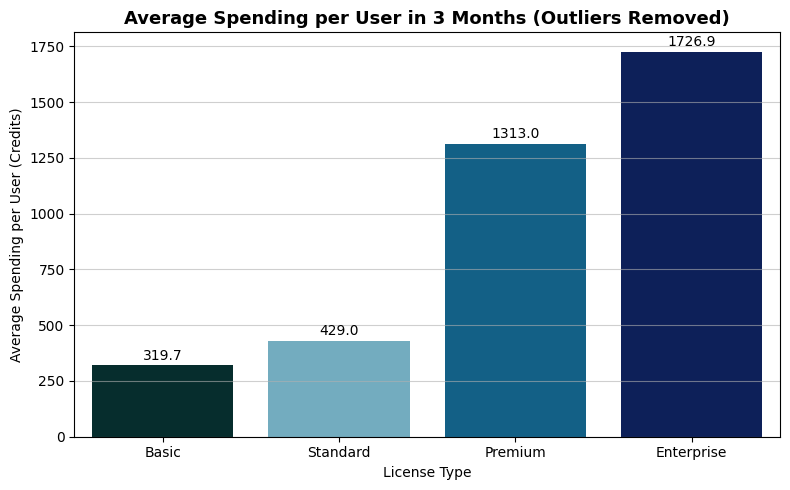

In [16]:
def remove_outliers(g):
    l, u = np.percentile(g['spent_amount'], [3, 97])
    return g[(g['spent_amount'] >= l) & (g['spent_amount'] <= u)]

user_spent = df.groupby(['uuid', 'license'])['spent_amount'].sum().reset_index()
user_spent_no_outliers = user_spent.groupby('license', group_keys=False).apply(remove_outliers)

avg_spent_no_outliers = user_spent_no_outliers.groupby('license', as_index=False)['spent_amount'].mean()
avg_spent_no_outliers.rename(columns={'spent_amount': 'avg_spent_per_user'}, inplace=True)

plt.figure(figsize=(8,5))
ax = sns.barplot(x='license', y='avg_spent_per_user', data=avg_spent_no_outliers,
                 hue='license', palette='ocean', order=order)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', label_type='edge', fontsize=10, padding=2)

plt.title('Average Spending per User in 3 Months (Outliers Removed)', fontsize=13, fontweight='bold')
plt.xlabel('License Type'); plt.ylabel('Average Spending per User (Credits)')
plt.grid(axis='y', alpha=0.6)
plt.tight_layout()
plt.show()


The data shown in the chart represents average user spending over a three-month period for different license types. By dividing these values by three, we can estimate the average monthly credit usage:

Basic: $\approx$ 107 credits/month

Standard: $\approx$ 143 credits/month

Premium: $\approx$ 438 credits/month

Enterprise: $\approx$ 576 credits/month

To maintain a clear and balanced structure while also encouraging users to upgrade to higher plans, I would recommend setting the monthly credit limits as follows:

Basic: 95 credits/month – lower limit designed to motivate plan upgrades

Standard: 140 credits/month

Premium: 500 credits/month

Enterprise: 700 credits/month - high limit, providing freedom and a sense of value for business customers

As a next step, it would be necessary to adjust the pricing of the plans to better reflect actual user resource consumption and ensure optimal profitability of each license tier.

## <h2 id="model-usage-analysis">4. Model Usage Analysis</h2>

#####  <h4 id="percentage-utilization">4.1 Percentage utilization of models across each license (based on the number of requests)</h4>

The chart shows the percentage distribution of model usage within each license: Basic, Standard, Premium and Enterprise.
Each pie chart represents how much of the total number of requests for a given license comes from each model.

The data were prepared as follows:

1. The total number of requests (requests_cnt) was summed for each model within each license.

2. The overall total number of requests was calculated per license.

3. The percentage share of each model was computed as the ratio of its request count to the total request count in that license.


Total model usage (requests_cnt) per model per license:
       license    model  total_requests
0        Basic  Model_A        181463.0
1        Basic  Model_B        104788.0
2        Basic  Model_C        366564.0
3        Basic  Model_D        333519.0
4        Basic  Model_E         91789.0
5   Enterprise  Model_A        309526.0
6   Enterprise  Model_B        294919.0
7   Enterprise  Model_C        498204.0
8   Enterprise  Model_D        548537.0
9   Enterprise  Model_E        274188.0
10     Premium  Model_A        258014.0
11     Premium  Model_B        172656.0
12     Premium  Model_C        676182.0
13     Premium  Model_D        406016.0
14     Premium  Model_E        206760.0
15    Standard  Model_A        242930.0
16    Standard  Model_B        158008.0
17    Standard  Model_C        400846.0
18    Standard  Model_D        606078.0
19    Standard  Model_E        161064.0

Total requests per license:
      license  total_requests_in_license
0       Basic                  10

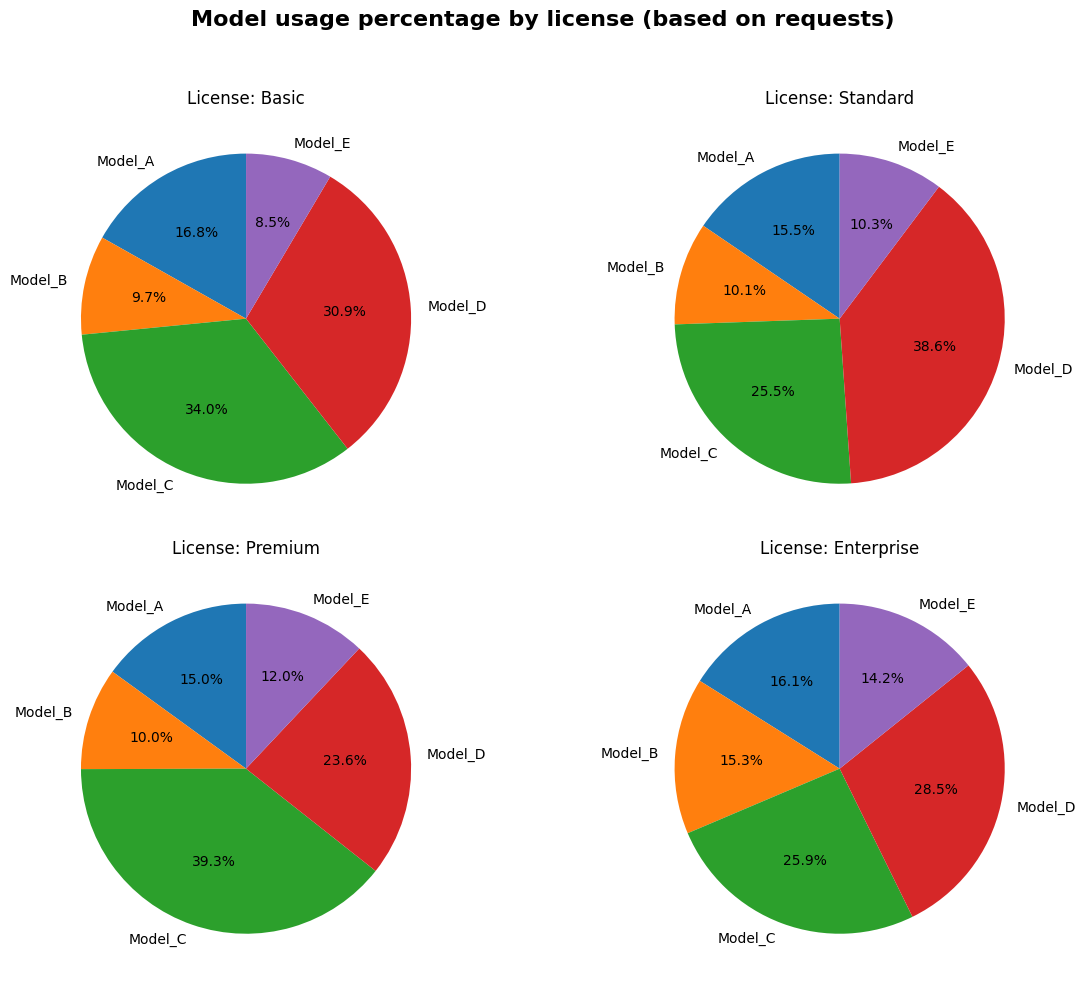

In [17]:
model_usage = df.groupby(['license', 'model'])['requests_cnt'].sum().reset_index(name='total_requests')
print("\nTotal model usage (requests_cnt) per model per license:")
print(model_usage)

license_totals = model_usage.groupby('license')['total_requests'].sum().reset_index(name='total_requests_in_license')
print("\nTotal requests per license:")
print(license_totals)

merged = pd.merge(model_usage, license_totals, on='license', how='left')
merged['percent_of_requests'] = (merged['total_requests'] / merged['total_requests_in_license']) * 100

order = [lic for lic in order if lic in merged['license'].unique()]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Model usage percentage by license (based on requests)", fontsize=16, fontweight='bold')
axes = axes.flatten()

for i, license_name in enumerate(order[:4]):
    data = merged[merged['license'] == license_name]
    axes[i].pie(data['percent_of_requests'], labels=data['model'], autopct='%1.1f%%', startangle=90)
    total_req = int(data['total_requests_in_license'].iloc[0])
    axes[i].set_title(f'License: {license_name.capitalize()}')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show(block=True)

**Conclusions:**
1. The most frequently used models across all license types are Model C and Model D. This indicates that they have the highest business and technological value for most clients. Even users on lower-tier plans (Basic and Standrad) make intensive use of these models’ features — it may be worth introducing a “lite” version in those plans.

2. Model A, B and E are used less often (around 10–17%), which may suggest that they are more specialized or less relevant for everyday tasks.

3. In the case of enterprise license diversity in usage of models increased. Which could mean that users in this group do not focus on a single solution but instead make conscious choices of models based on specific needs and task characteristics.

**Recomendations**

1. Focus on the development and optimization of Models C and D – these are the key products driving the highest user engagement. Introduce a “Lite” version for lower-tier plans to encourage upgrades to higher subscriptions.

2. Analyze the role of Models A, B, and E in lower-tier plans to determine whether they serve niche purposes and meet the needs of specific customer segments. If demand remains low, consider repositioning or phasing them out to optimize the product portfolio.

3. Examine the usage of Model A, B and E within Enterprise licenses. Based on the insights, further develop the model as a complementary tool tailored for the Enterprise segment.


#####  <h4 id="total-credits-spent-per-model">4.2 Total credits spent per model</h4>
The purpose of the following analysis is to determine which model generates the highest costs for the user. We compare the total number of credits spent across different models to identify those that, despite a smaller share of requests, may be the most expensive.

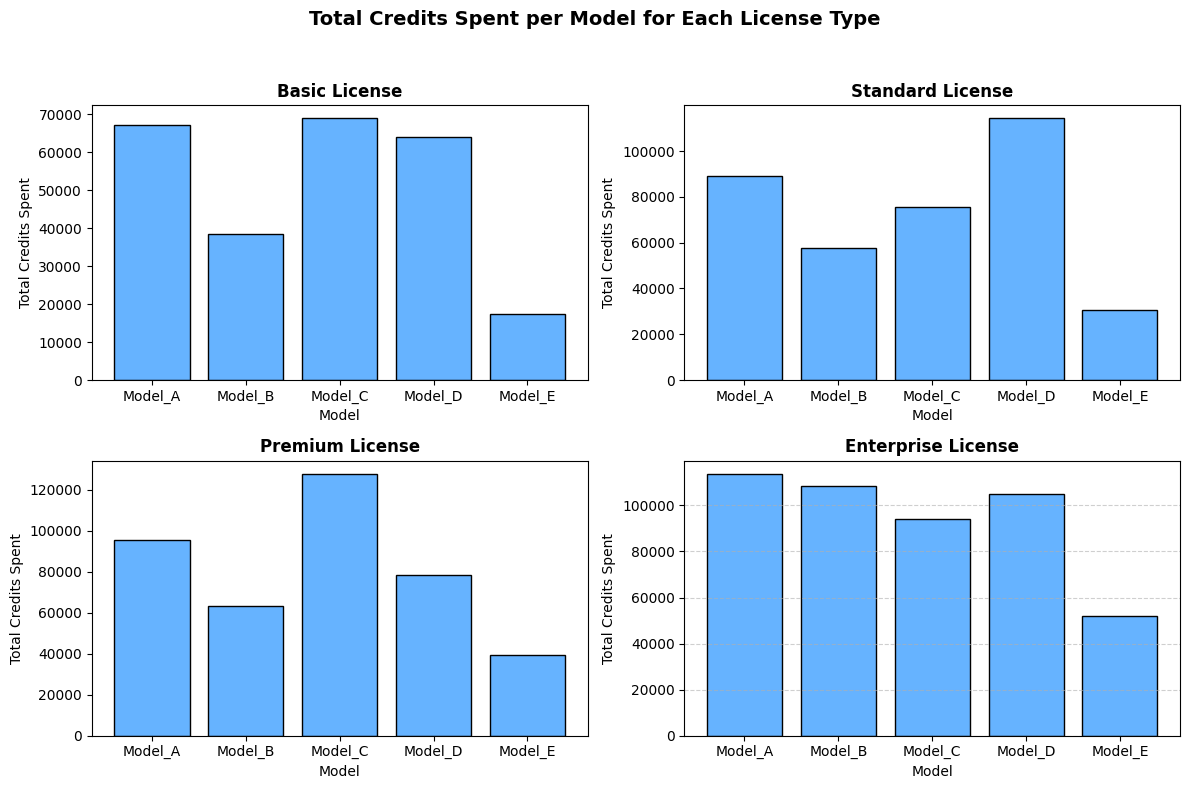

In [18]:
grouped = df.groupby(["license", "model"])["spent_amount"].sum().reset_index()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, license_type in enumerate(order):
    subset = grouped[grouped["license"] == license_type]
    
    if not subset.empty:
        axes[i].bar(subset["model"], subset["spent_amount"], color = '#66b3ff', edgecolor="black")
        axes[i].set_title(f"{license_type} License", fontsize=12, fontweight="bold")
        axes[i].set_xlabel("Model")
        axes[i].set_ylabel("Total Credits Spent")

plt.suptitle("Total Credits Spent per Model for Each License Type", fontsize=14, fontweight="bold")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

The graph shows that some models generate significantly higher costs despite lower usage levels.

For instance, under the Basic license, Model A accounts for only about 16.8% of all requests, yet its total spending is comparable to Model C, which represents 34% of the usage. A similar pattern can be observed in other license categories, where the relationship between usage share and cost is not proportional.

This indicates that certain models are considerably more expensive per request, highlighting the need for further investigation into the average cost per request in the following section of the report (see point 4.4 and 5.3).

#####  <h4 id="which-models">4.3 Which Models Do Users Prefer? Feature-Based Usability Analysis</h4>

This section focuses on comparing models across different license tiers in terms of how their features are utilized.
For each model, the total number of feature requests was analyzed to determine which models are used most frequently and which features deliver the greatest value within each license type.
This breakdown helps identify top-performing models and key features that drive user engagement and overall system value.
The insights gained from this analysis can support product strategy, feature prioritization and future model development decisions.

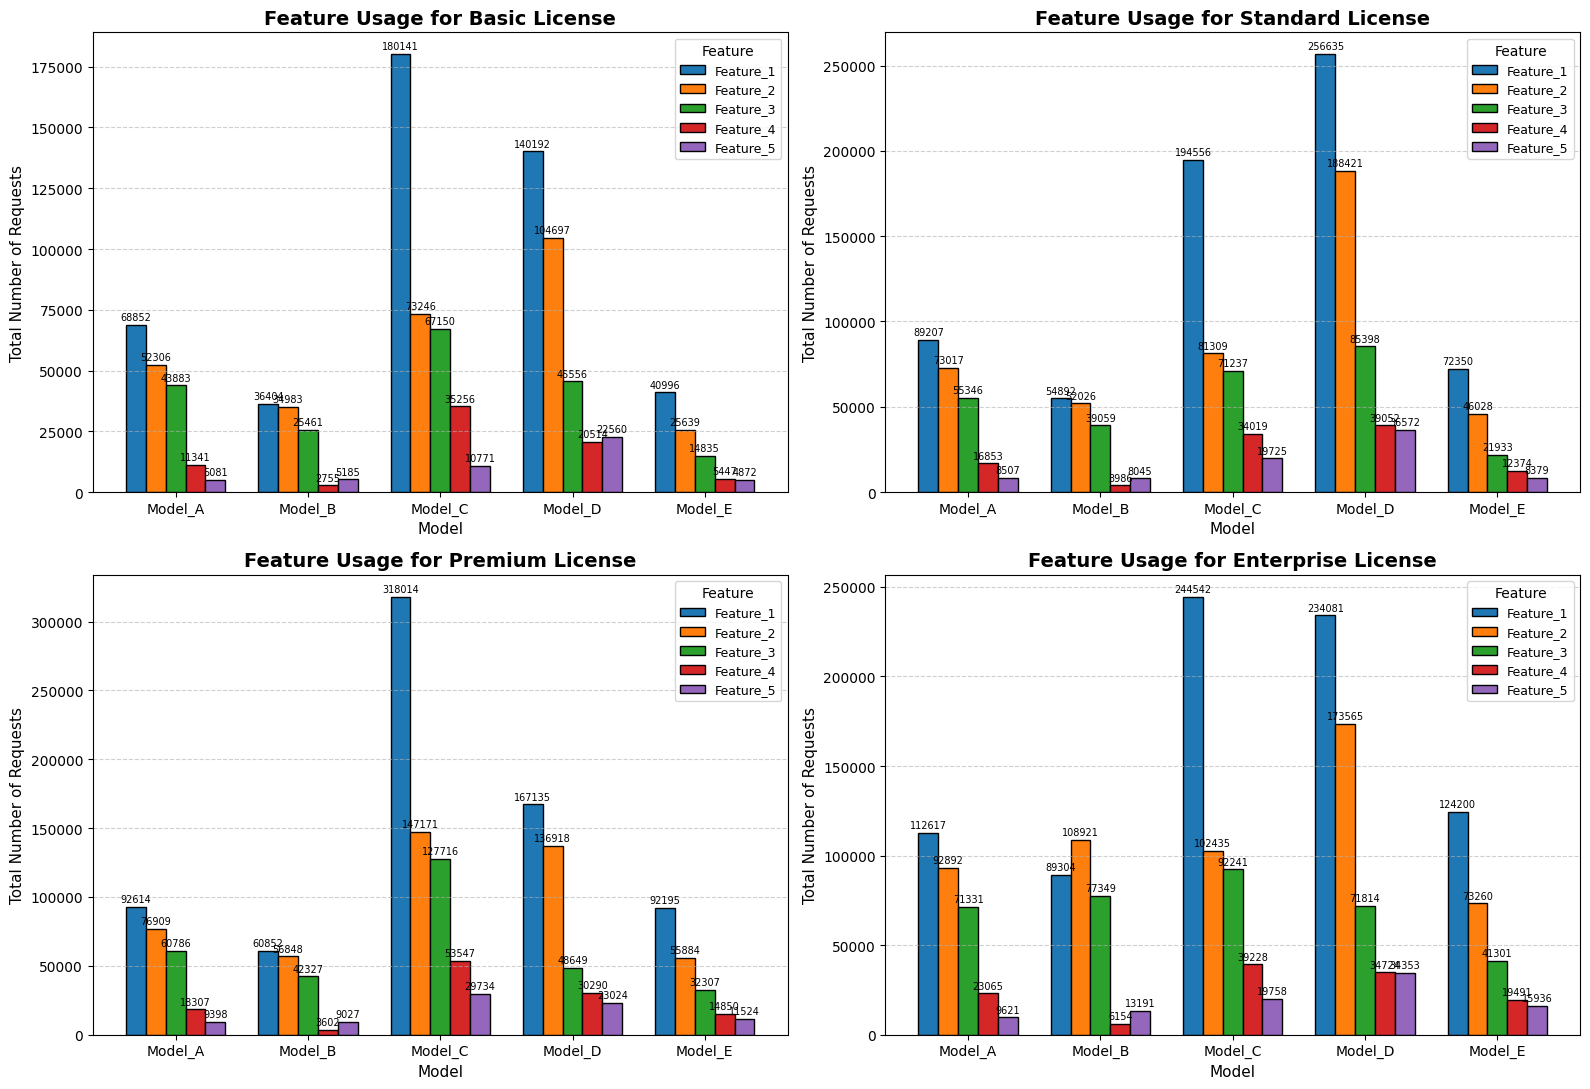

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for ax, lic in zip(axes, order):
    lic_df = df[df['license'] == lic]

    grouped = (
        lic_df
        .groupby(['model', 'feature'])['requests_cnt']
        .sum()
        .unstack(fill_value=0)
    )

    grouped.plot(kind='bar', ax=ax, width=0.75, edgecolor='black')

    ax.set_title(f'Feature Usage for {lic} License', fontsize=14, fontweight='bold')
    ax.set_xlabel('Model', fontsize=11)
    ax.set_ylabel('Total Number of Requests', fontsize=11)
    ax.tick_params(axis='x', labelrotation=0, labelsize=10)
    ax.tick_params(axis='y', labelsize=10)
    ax.legend(title='Feature', title_fontsize=10, fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.6)

    for container in ax.containers:
        ax.bar_label(container, fmt='%d', label_type='edge', fontsize=7, padding=2)

plt.tight_layout()
plt.show()


**Conclusions:**

1. Feature 1 – the key function across all licenses, most frequently used in Models C and D.

    Regardless of license type, Feature 1 remains the dominant functionality.
    Users in every tier most often access it through Model C and Model D, highlighting their central importance in the system architecture.

2. Feature 2 – most commonly used in Model D across nearly all license levels.

    In almost every license category, Feature 2 reaches its highest utilization in Model D, suggesting better compatibility or performance for this feature within that model.
    Its growing presence in Standard and Premium licenses points to its importance in more complex workflows used by mid- and high-tier customers.

3. Feature 3 – least used in Model E, most active in Model C within the Premium license.

    Among Premium users, Feature 3 is most frequently accessed through Model C, while in other licenses its usage remains fairly balanced across models — with the notable exception of Model E, where it is rarely used.
    This may indicate limited applicability of Model E for this feature or lower relevance in its use cases.

4. Feature 4 and Feature 5 – the least utilized features across all models and licenses.

    Feature 4 and Feature 5 consistently show the lowest levels of usage.
    When used, they appear mainly within Models B and C, with slightly higher activity in higher-tier licenses.

**Summary of model–feature–license relationships**

Models C and D are the most versatile, supporting a broad range of features.

Feature 1 remains the key driver of activity across all license levels.
As the license tier increases, so does the diversity of utilized features, indicating more complex and sophisticated usage patterns in higher plans.

**Recomendations:**

1. Strengthen the development and maintenance of Feature 1

    Since Feature 1 is a key function in every license type and across all models (especially C and D), it is important to maintain it's high quality, stability and performance.
    It is worth investing in further improvements and usage analysis, as it generates the greatest business value and user satisfaction.

2. Develop Model C and Model D as the main functional platforms

    Models C and D play a central role in supporting most features.
    It is advisable to focus technological development, performance optimization, and testing of new functionalities on these models.

3. Increase the attractiveness and accessibility of Feature 4 and Feature 5

    The low popularity of these features suggests that they may be too hidden, unintuitive or not well aligned with user needs.
    It would be beneficial to conduct a UX study or business value analysis to determine whether they can be simplified, better integrated with the popular models (C and D), or possibly replaced with more useful features.

#####  <h4 id="average-cost-per-request-by-model">4.4 Average Cost per Request by Model</h4>
The chart shows the average cost per request for each model.
This value was obtained by dividing the total spending (spent_amount) by the number of requests (requests_cnt) for each record in the dataset and then calculating the mean for every model.

As a result, the chart highlights how much a single request costs on average for each model, providing insight into their relative cost efficiency.

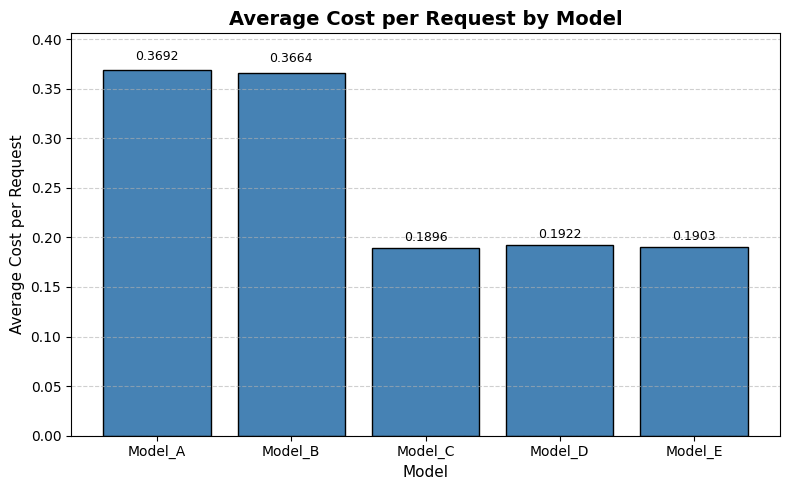

In [20]:
df["cost_per_request"] = df["spent_amount"] / df["requests_cnt"]
model_avg_cost = (
    df.groupby("model")["cost_per_request"]
    .mean()
    .reindex(sorted(df["model"].unique()))
)

plt.figure(figsize=(8, 5))
bars = plt.bar(model_avg_cost.index, model_avg_cost.values, color="steelblue", edgecolor="black")

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + (height * 0.02),
             f"{height:.4f}", ha="center", va="bottom", fontsize=9)

plt.title("Average Cost per Request by Model", fontsize=14, fontweight="bold")
plt.xlabel("Model", fontsize=11)
plt.ylabel("Average Cost per Request", fontsize=11)
plt.ylim(bottom=0, top=model_avg_cost.max() * 1.1)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

As we can see, Models A and B generate the highest cost for users, while other around half as much. However we also need to analyse which features were used in each model, because it could impact the result, it depends on the average cost of each feature and its usage for each model, which I will check in another chapter to find the reason for these differences.

## <h2 id="further-features">5. Further analysis of features accross different data </h2>
In this chapter, I conduct a deeper analysis to understand how different features are used and how they contribute to overall spending.
The goal is to identify which features are most desired by users, which generate the highest profit and how the credit cost per usage varies between them.

#####  <h4 id="feture-usage">5.1 Feature Usage and Associated Spending across Licenses</h4>
The analysis presents the number of requests and total spending for each feature across license types. The goal is to assess the intensity of feature usage and the related costs.

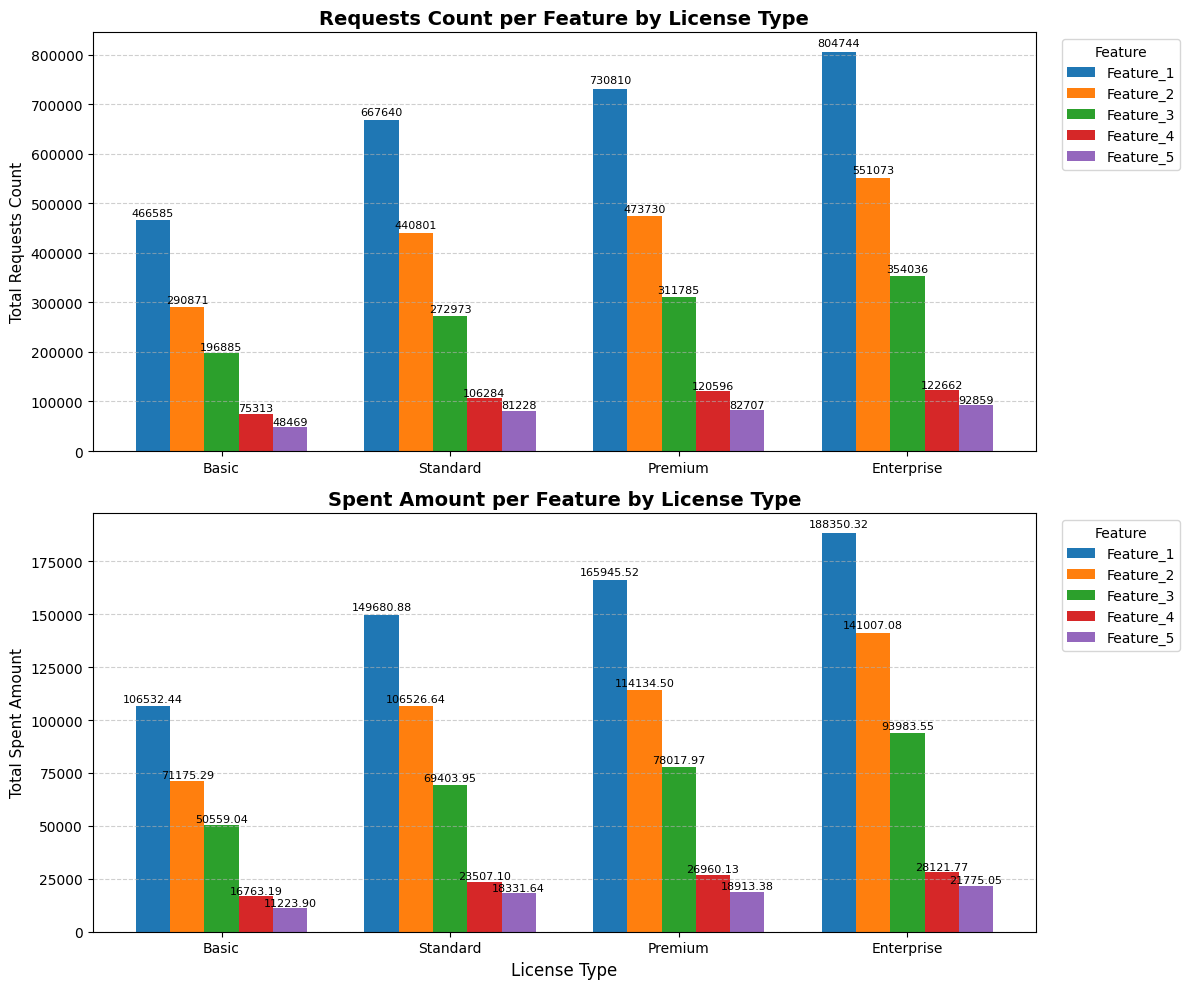

In [21]:
feature_order = sorted(df["feature"].unique())[:5]
metrics = [("requests_cnt", "Requests Count"), ("spent_amount", "Spent Amount")]

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for ax, (metric, title) in zip(axes, metrics):
    data = df.groupby(["license", "feature"])[metric].sum().unstack(fill_value=0)
    data = data.reindex(index=order, columns=feature_order, fill_value=0)
    
    x = np.arange(len(order))
    width = 0.15
    offsets = np.linspace(-width*2, width*2, len(feature_order))
    
    for i, f in enumerate(feature_order):
        vals = data[f].values
        bars = ax.bar(x + offsets[i], vals, width, label=f)
        for b in bars:
            h = b.get_height()
            if h > 0:
                ax.text(b.get_x() + b.get_width()/2, h + h*0.01,
                        f"{int(h) if metric=='requests_cnt' else f'{h:.2f}'}",
                        ha="center", va="bottom", fontsize=8)
    
    ax.set_title(f"{title} per Feature by License Type", fontsize=14, fontweight="bold")
    ax.set_ylabel(f"Total {title}", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(order)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(title="Feature", bbox_to_anchor=(1.02, 1), loc="upper left")

axes[-1].set_xlabel("License Type", fontsize=12)
plt.tight_layout()
plt.show()


It is evident that across all license types, users utilize the features in a very similar pattern — the differences lie mainly in the scale of usage. However, there is a significant gap between the most and least used features, highlighting strong user preferences and potential to optimize underutilized functionalities.

**Recomandation:**

Focus on enhancing the most frequently used features (Feature_1 and Feature_2) and to investigate the reasons behind the low usage of Feature 4 and 5 to determine whether they should be improved or promoted.

#####  <h4 id="total-requests-and-spent-amount-per-feature">5.2 Total Requests and Spent Amount per Feature</h4>
Additionally, a summary of the total number of requests and total credits spent is included for each feature.
This graph will show us clear summary and will confirm, which features were the most desired by users and which generated the highest costs.

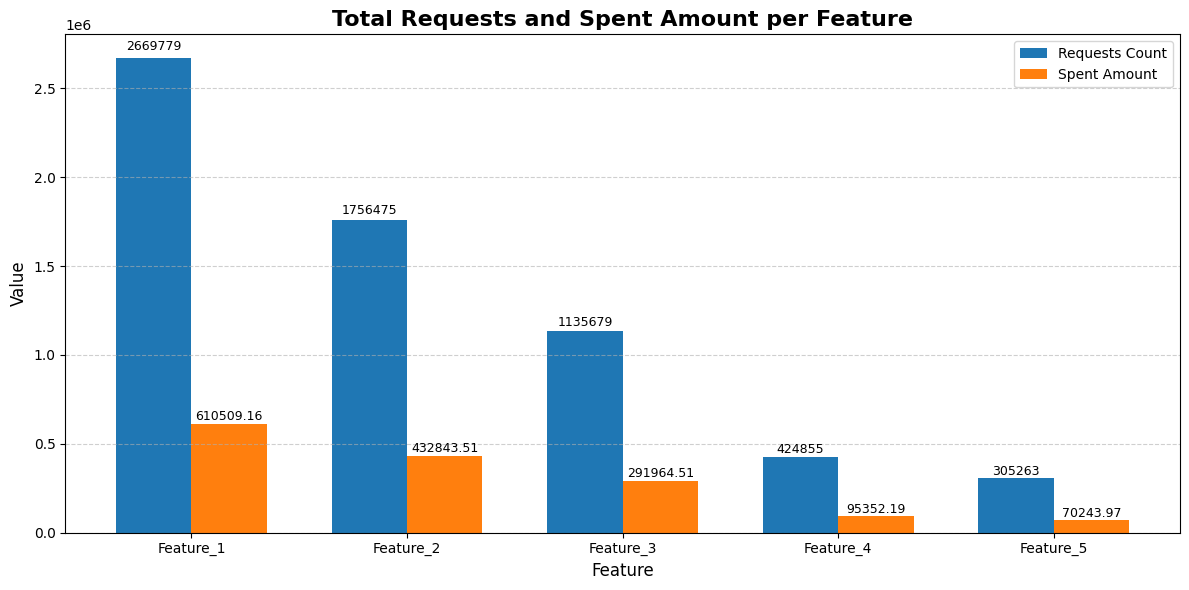

In [22]:
feature_stats = (
    df.groupby("feature")[["requests_cnt", "spent_amount"]]
    .sum()
    .reindex(sorted(df["feature"].unique()))
)

x = np.arange(len(feature_stats))
width = 0.35
fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, feature_stats["requests_cnt"], width, label="Requests Count")
bars2 = ax.bar(x + width/2, feature_stats["spent_amount"], width, label="Spent Amount")

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + (height * 0.01),
                f"{int(height) if bars is bars1 else f'{height:.2f}'}",
                ha="center", va="bottom", fontsize=9)

ax.set_title("Total Requests and Spent Amount per Feature", fontsize=16, fontweight="bold")
ax.set_xlabel("Feature", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(feature_stats.index)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()


As we can see feature usage decreases gradually. It means that it is worth to further develop feature 1 and 2 becase they generates the highest revenue.

#####  <h4 id="average-cost-per-request-by-feature">5.3 Average Cost per Request by Feature</h4>
The chart presents the average cost per request for each feature.
These values were calculated by dividing the total spending (spent_amount) by the number of requests (requests_cnt) for every record in the dataset and then computing the mean value for each feature.

As a result, the chart illustrates how much a single request costs on average for each feature.

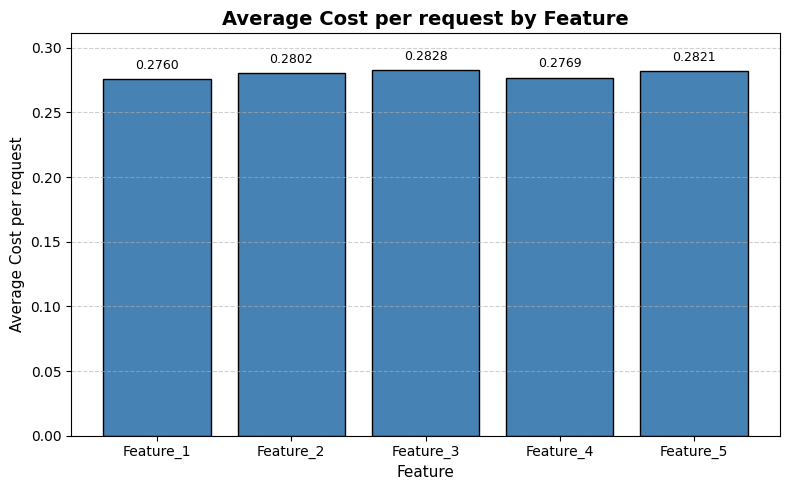

In [23]:
df["cost_per_request"] = df["spent_amount"] / df["requests_cnt"]
feature_avg_cost = (
    df.groupby("feature")["cost_per_request"]
    .mean()
    .reindex(sorted(df["feature"].unique()))
)

plt.figure(figsize=(8, 5))
bars = plt.bar(feature_avg_cost.index, feature_avg_cost.values, color="steelblue", edgecolor="black")

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + (height * 0.02),
             f"{height:.4f}", ha="center", va="bottom", fontsize=9)

plt.title("Average Cost per request by Feature", fontsize=14, fontweight="bold")
plt.xlabel("Feature", fontsize=11)
plt.ylabel("Average Cost per request", fontsize=11)
plt.ylim(bottom=0, top=feature_avg_cost.max() * 1.1)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

Based on the graph, we can see that the values ​​are virtually identical. Therefore, the system demonstrates a balanced cost distribution across all features.

**To sum up**

Now it can be said that only the used model has influence on the credit spent amount. So models A and B (see point 4.4) generate the higest costs for user. 

**Recomandation**

It would be worthwhile to further investigate whether the increased cost associated with models A and B translates into a corresponding improvement in performance or output quality.
If these models indeed deliver better results, the higher expenditure may be justified. However, if no significant performance gains are observed, it would be advisable to consider switching to more cost-efficient models or optimizing the current workflow to reduce unnecessary credit consumption.

## <h2 id="mulitply-license">6. Analysis of Users with Multiple License</h2>

In [24]:
users_with_changed_license = license_counts_per_user[license_counts_per_user > 1]
max_license_changes = users_with_changed_license.max()

print("Number of users who changed their license type:", num_users_changed_license)
print("Maximum number of different licenses for a single user:", max_license_changes)

Number of users who changed their license type: 57
Maximum number of different licenses for a single user: 2


#####  <h4 id="number-of-change">6.1 Number of License Changes per User</h4>

First of all I checked how many times users changed their licenses over a three-month period (with dates sorted chronologically). Each user used a maximum of two different licenses. Below is a chart sorted by the number of changes with all users.

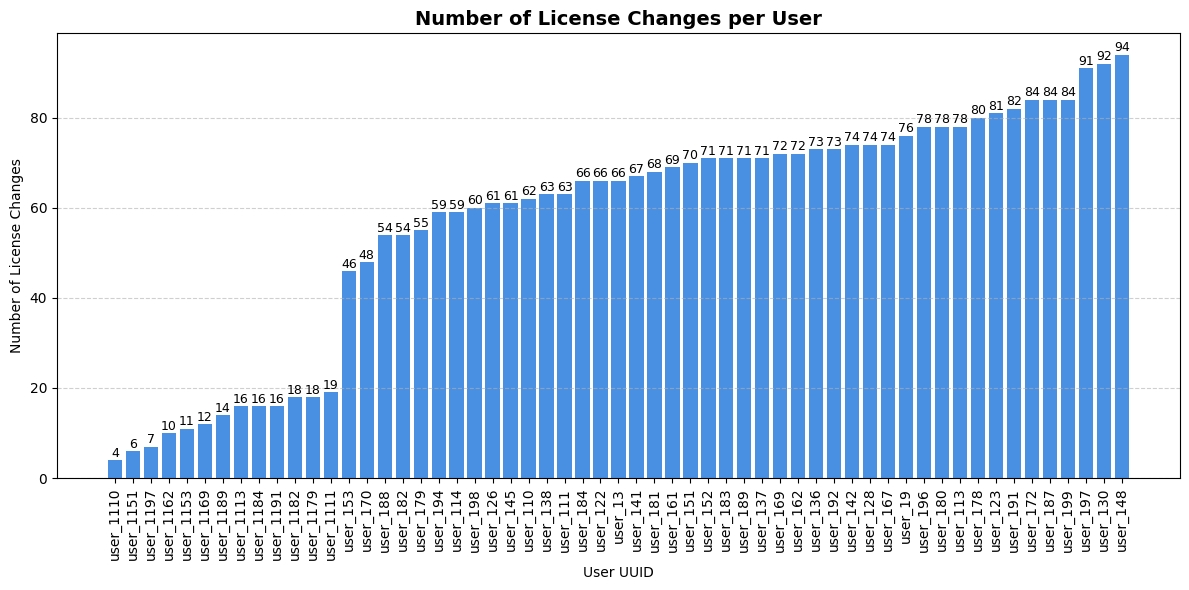

In [25]:
df_copy2 = df.copy()

license_counts_per_user = df_copy2.groupby("uuid")["license"].nunique()
users_with_multiple_licenses = license_counts_per_user[license_counts_per_user > 1].index

df_copy2 = df_copy2[df_copy2["uuid"].isin(users_with_multiple_licenses)].copy()
df_copy2 = df_copy2.sort_values(["uuid", "day_id"])
df_copy2["license_change"] = (df_copy2.groupby("uuid")["license"].transform(lambda x: x.ne(x.shift()).cumsum()))

license_change_counts = df_copy2.groupby("uuid")["license_change"].max() - 1
license_change_counts = license_change_counts.sort_values(ascending=True)


plt.figure(figsize=(12, 6))
bars = plt.bar(license_change_counts.index, license_change_counts.values, color="#4A90E2")
plt.title("Number of License Changes per User", fontsize=14, fontweight="bold")
plt.xlabel("User UUID")
plt.ylabel("Number of License Changes")
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05, f"{int(height)}",
             ha='center', va='bottom', fontsize=9)
    
plt.tight_layout()
plt.show()


The data indicates that license changes occurred quite frequently, suggesting that users dynamically adjusted their license types based on their current needs.

To understand the reasons behind these frequent changes, further analysis was performed comparing total_request, total_credits_spent, days_on_license and the types of licenses used by users across different models. The goal was to identify the key factors that may have influenced users’ decisions to switch licenses.

#####  <h4 id="comparison-of-two-license">6.2 Comparison of Two License Usages in Requests and Spending</h4>
The aim of this comparison is to identify whether there are clear patterns indicating the dominance of one license over the other, to understand the possible reasons behind frequent switching between plans and to examine what such behavior may suggest about user motivations or usage patterns. On the chart, the higher-tier licence of the two is positioned in the upper part of each bar.

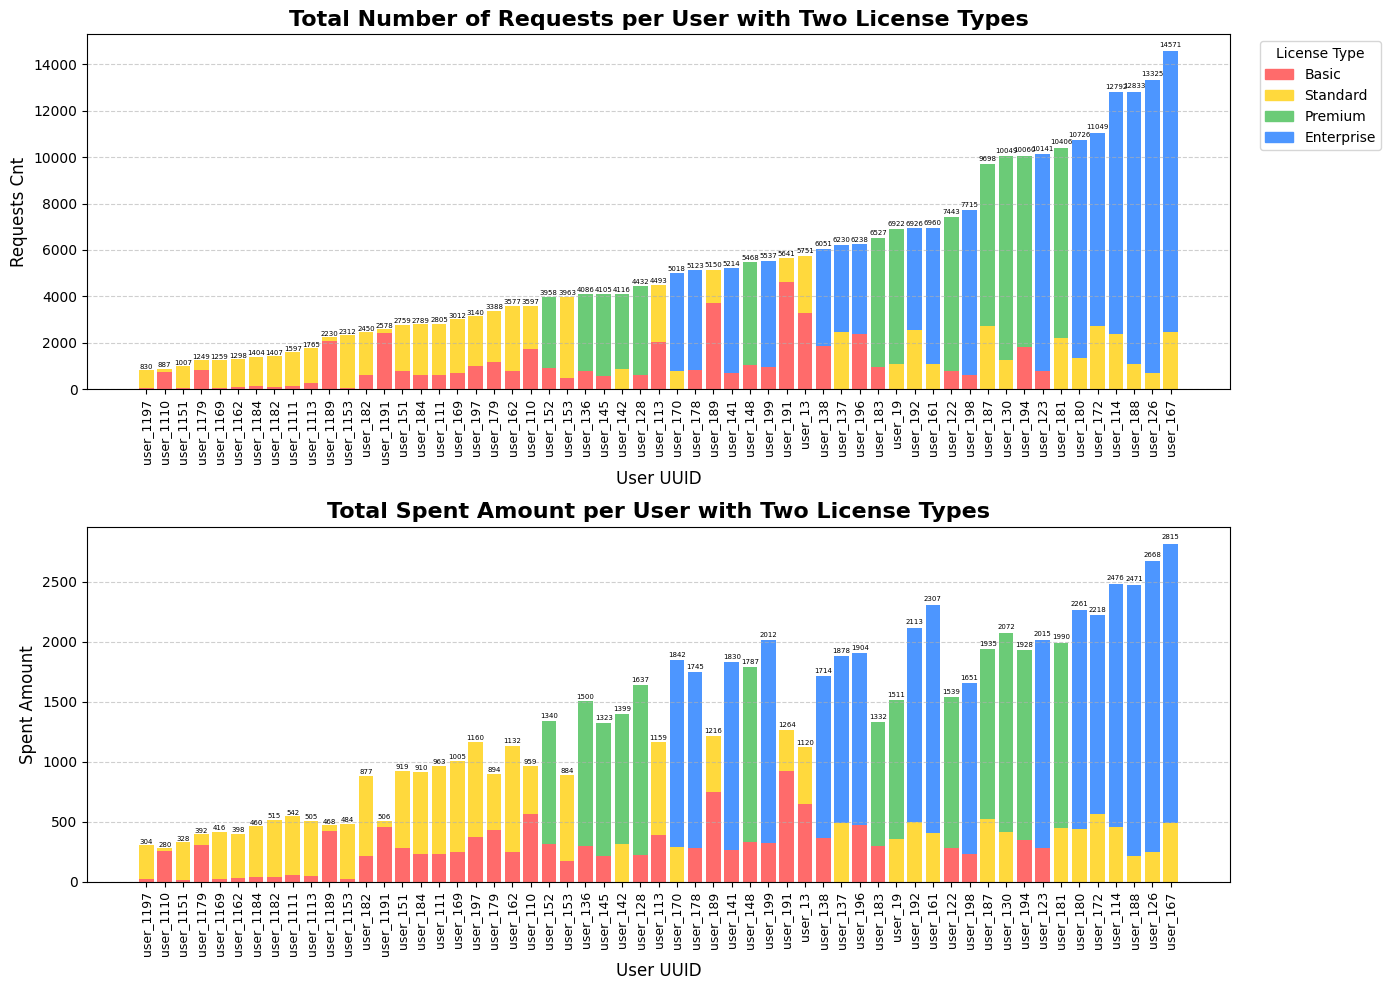

Users, for which one license dominates over another: based on requests >=70%: 47
Percentage of such users: 82.46%


In [26]:
license_colors = {"Basic": "#FF6B6B", "Standard": "#FFD93D", "Premium": "#6BCB77", "Enterprise": "#4D96FF"}

license_counts_per_user = df_copy2.groupby("uuid")["license"].nunique()
users_with_two_licenses = license_counts_per_user[license_counts_per_user == 2].index
df_copy2 = df_copy2[df_copy2["uuid"].isin(users_with_two_licenses)].copy()

def plot_license_stacked(df, value_column, title, ax, order, license_colors, user_order=None):
    license_sums = (df.groupby(["uuid", "license"])[value_column].sum().unstack(fill_value=0))
    license_sums = license_sums.reindex(columns=order, fill_value=0)
    license_sums["total"] = license_sums.sum(axis=1)

    if user_order is not None:
        license_sums = license_sums.loc[user_order]
    else:
        license_sums = license_sums.sort_values("total", ascending=True)

    for user in license_sums.index:
        user_data = license_sums.loc[user]
        used_licenses = user_data[user_data > 0].drop("total", errors="ignore").index.tolist()

        if len(used_licenses) == 2:
            used_licenses = sorted(used_licenses, key=lambda x: order.index(x))
            low_lic, high_lic = used_licenses
            low_val = user_data[low_lic]
            high_val = user_data[high_lic]
            total_val = low_val + high_val

            ax.bar(user, low_val, color=license_colors[low_lic])
            ax.bar(user, high_val, bottom=low_val, color=license_colors[high_lic])
            ax.text(user, total_val + (total_val * 0.01), f"{int(total_val)}",
                    ha="center", va="bottom", fontsize=5)

    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_ylabel(value_column.replace("_", " ").title(), fontsize=12)
    ax.set_xlabel("User UUID", fontsize=12)
    ax.tick_params(axis="x", rotation=90, labelsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.set_xticks(range(len(license_sums.index)))
    ax.set_xticklabels(license_sums.index)
    return license_sums.index

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

user_order = plot_license_stacked(df_copy2, "requests_cnt", "Total Number of Requests per User with Two License Types", axes[0], ["Basic", "Standard", "Premium", "Enterprise"], license_colors)
_ = plot_license_stacked(df_copy2, "spent_amount", "Total Spent Amount per User with Two License Types", axes[1], ["Basic", "Standard", "Premium", "Enterprise"], license_colors, user_order=user_order)

handles = [plt.Rectangle((0, 0), 1, 1, color=license_colors[lic]) for lic in ["Basic", "Standard", "Premium", "Enterprise"]]
axes[0].legend(handles, ["Basic", "Standard", "Premium", "Enterprise"], title="License Type", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

user_license_sums = df_copy2.groupby(["uuid", "license"])["requests_cnt"].sum()
pivot = user_license_sums.unstack(fill_value=0)
pivot = pivot.loc[users_with_two_licenses]
dominant_users_count = 0

for user, row in pivot.iterrows():
    used = row[row > 0]
    if len(used) == 2:
        total = used.sum()
        max_share = used.max() / total

        if max_share >= 0.70:
            dominant_users_count += 1
percentage = (dominant_users_count / num_users_changed_license) * 100

print(f"Users, for which one license dominates over another: based on requests >=70%: {dominant_users_count}")
print(f"Percentage of such users: {percentage:.2f}%")

**request_cnt:**
For a large share of users, one license clearly dominates in terms of usage. This indicates a lack of balanced use between the two plans, which may result from temporary needs or attempts to optimize costs. However, the dominant license is not always the higher-tier one, which may be related to users misunderstanding how the plans work, potentially caused by unclear or insufficient presentation of the license conditions.

**spent_amount:**
In the case when the dominating license was of upper tiers (premium, enterprise), the credit spent amount was higher. That is why the two graphs are not exact. This may be also due to the usage of different models or/and features.

**Recomandations:**

Reduce unnecessary switching between plans:

- clearer differentiation between tiers

Consider offering a hybrid or flexible tier:

- for users who mostly use one plan but occasionally require higher-tier features.

Improve plan clarity and pricing transparency

- frequent switching may indicate that users do not clearly understand which tier best meets their needs.

#####  <h4 id="model-usage-by-licenses-for">6.3 Model usage by licenses for selected users</h4>

To find the reason for these frequent changes, we should look at diffrences between what licenses were used for particular Models. The results are presented for 9 users selected to represent the most diverse usage patterns observed in the earlier sections. Only models are analysed, due to the fact that features were proven earlier to not have any impact on credit spent amount.

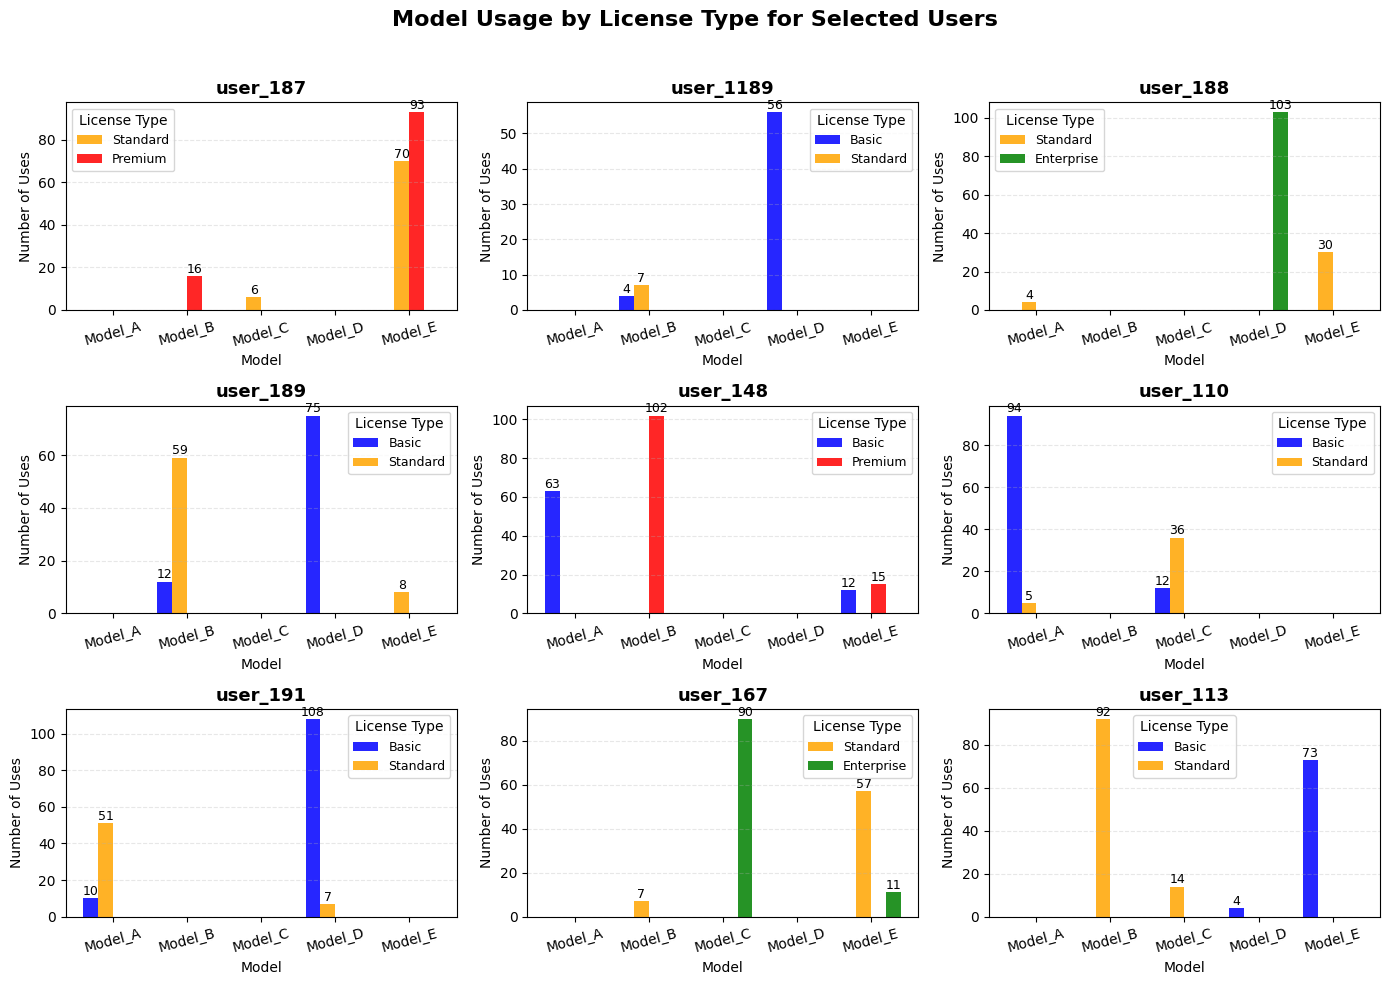

In [27]:
all_models = sorted(df_copy2["model"].unique())
users = {"user_148", "user_113", "user_187", "user_1189", "user_189", "user_167", "user_191", "user_188", "user_110"}
color_map = {
    "basic": "blue",
    "standard": "orange",
    "premium": "red",
    "enterprise": "green"}

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for idx, user_id in enumerate(users):
    ax = axes[idx]

    user_df = df_copy2[df_copy2["uuid"] == user_id].copy()
    model_usage = user_df.groupby(["license", "model"]).size().reset_index(name="usage_count")

    full_index = pd.MultiIndex.from_product([order, all_models], names=["license", "model"])
    model_usage = model_usage.set_index(["license", "model"]).reindex(full_index, fill_value=0).reset_index()

    used_licenses = model_usage.groupby("license")["usage_count"].sum()
    used_licenses = used_licenses[used_licenses > 0].index.tolist()

    x = np.arange(len(all_models))
    width = 0.8 / len(order)

    for j, lic in enumerate(order):
        lic_df = model_usage[model_usage["license"] == lic]
        counts = lic_df["usage_count"].values
        color = color_map[lic.lower()]

        offset = (j - len(order) / 2) * width + width / 2
        bars = ax.bar(x + offset, counts, width, label=lic, color=color, alpha=0.85)

        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.text(bar.get_x() + bar.get_width()/2, height + 0.1, f"{int(height)}",
                        ha='center', va='bottom', fontsize=9)

    ax.set_title(f"{user_id}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Model")
    ax.set_ylabel("Number of Uses")
    ax.set_xticks(x)
    ax.set_xticklabels(all_models, rotation=15)
    ax.grid(axis="y", alpha=0.3, linestyle="--")

    handles, labels = ax.get_legend_handles_labels()
    used_handles = [h for h, l in zip(handles, labels) if l in used_licenses]
    used_labels = [l for l in labels if l in used_licenses]
    ax.legend(used_handles, used_labels, title="License Type", fontsize=9)

plt.suptitle("Model Usage by License Type for Selected Users", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Such users mostly use specific license types for particular models. The reason might be to lower the cost. Users have changed their licenses very frequently. Although a small amount of users focused on the same model using two licenses. This also indicates that some people don't clearly understand differences between licence tiers. It may be beneficial to introduce a clearly defined, cyclical validity period for each license, ensuring that users remain on a given plan for a full, predetermined duration.



## <h2 id="summary-and-recomandation">7. Summary and recomandation</h2>
To summarise, the analysis of user activity within the IDE environment from March to May 2025 revealed key usage patterns of machine learning (ML) models and platform features. These patterns vary according to license type (Basic, Standard, Premium, Enterprise), intensity of system, resource utilization and user preferences. The following conclusions and recommendations consolidate the most important insights from the report, highlighting areas of greatest business impact, opportunities for optimization and actions to enhance product development.

## <h4 id="conclusions">7.1 Conclusions from every chapter</h4>
User Analysis:

- The largest user base consists of Basic and Standard license holders.

- User activity, measured by the number of requests, is highest on weekdays (Monday to Friday) and drastically decreases on weekends, suggesting the tool is primarily used for work purposes.

- The growth in active users over time (March–May) primarily concerns the lower-tier plans (Basic and Standard), while higher-tier plans (Premium and Enterprise) maintain a stable level of activity.

Model and Cost Analysis:

- Model C and Model D are the most frequently used models across all license plans, indicating their highest business and technological value for customers.

- Model A and Model B generate the highest cost per request (the average cost is 3–4 times higher than Model D), despite their lower overall usage frequency.

- Cost differences are driven by the specific model used, not by the specific Feature, as the average cost per request for all features is nearly identical.

Feature Analysis:

- Feature 1 is the dominant and key feature used across all license tiers and models (especially in Models C and D).

- Feature 4 and Feature 5 show low popularity.

License Change Analysis:

- A small group of users (57 individuals) changed their licenses over the three months.

- The changes for most users were frequent and happened between two licence types 

- These users often select different plans for specific models, which could be a cost-saving strategy but also suggests unclear differentiation or understanding of the license tiers.

## <h4 id="recommendations">7.2 Recommendations:</h4>
**1. Introduce a 'Lite' version of Model C and D for lower licence tiers**

The most-used models are the main drivers of user engagement. Introducing 'Lite' versions for lower plans could encourage Basic/Standard users to upgrade.

**2. Enhance the attractiveness of Premium/Enterprise plans**

Activity growth is concentrated in lower tiers. Clearer unique and attractive benefits (e.g., additional advanced features or lower costs for Models A/B) can motivate upgrades.

**3. Reduce compute capacity during weekends**

Activity drops by more than 3x on weekends. Scheduling maintenance, updates and non-resource-intensive deployments during this time can lower operational costs.

**4. Focus on Model C and D and Feature 1**

Models C and D are the primary functional platforms and Feature 1 is crucial for most users. Investments in the stability and performance of these areas will result in the greatest business value and user satisfaction.

**5. Investigate and improve Feature 4 and Feature 5**

Low popularity suggests these features might be hidden, unintuitive or misaligned with user needs. A UX analysis or better integration with models is recommended.

**6. Analyze the higher cost reason for Models A and B**

Models A and B are significantly more expensive per request. It should be investigated whether the higher cost translates into superior quality/performance. If not, consider cost optimization or transitioning to cheaper models.

**7. Improve plan clarity and consider a validity period**

Frequent license changes suggest users don't fully understand the differences. Better communication of differentiators and the introduction of a defined, cyclical validity period can reduce unnecessary switching.